In [1]:
import os
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


All libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
df=pd.read_csv("C:\Calibo\Phase2\DeepLearning\synthetic_cardiometabolic_neural_network_dataset.csv")

<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
C:\Users\KEERTHI\AppData\Local\Temp\ipykernel_36220\876589741.py:1: SyntaxWarning: invalid escape sequence '\C'
  df=pd.read_csv("C:\Calibo\Phase2\DeepLearning\synthetic_cardiometabolic_neural_network_dataset.csv")


In [3]:
df.shape

(8000, 14)

In [4]:
df.head()

,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
0,70,1,27.5,149,71,233,100,72,0,1,0,8.0,3,1
1,32,0,30.3,136,59,173,85,72,0,0,2,8.2,3,0
2,71,0,21.5,150,80,197,74,72,0,1,2,5.2,2,0
3,19,0,30.8,119,60,208,75,81,1,0,0,7.2,4,0
4,44,1,28.5,145,70,141,97,86,0,1,1,7.2,4,0


In [5]:
df.tail()

,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
7995,37,1,25.3,119,62,117,90,79,0,1,1,8.2,3,0
7996,71,1,25.5,140,83,232,101,67,1,1,2,5.5,4,0
7997,85,1,31.6,145,74,239,113,84,0,1,3,5.3,2,1
7998,43,0,28.0,136,69,177,86,82,0,0,2,6.6,3,0
7999,42,0,24.5,125,84,122,65,91,1,0,2,5.7,3,0


In [6]:
df.columns

Index(['age_years', 'sex_female', 'bmi', 'systolic_bp_mmHg',
       'diastolic_bp_mmHg', 'total_cholesterol_mg_dL', 'fasting_glucose_mg_dL',
       'resting_heart_rate_bpm', 'smoking_current',
       'family_history_cardiometabolic', 'physical_activity_level',
       'sleep_hours', 'stress_level_1_to_5', 'elevated_cardiometabolic_risk'],
      dtype='str')

In [7]:
df.dtypes

age_years                           int64
sex_female                          int64
bmi                               float64
systolic_bp_mmHg                    int64
diastolic_bp_mmHg                   int64
total_cholesterol_mg_dL             int64
fasting_glucose_mg_dL               int64
resting_heart_rate_bpm              int64
smoking_current                     int64
family_history_cardiometabolic      int64
physical_activity_level             int64
sleep_hours                       float64
stress_level_1_to_5                 int64
elevated_cardiometabolic_risk       int64
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age_years                       8000 non-null   int64  
 1   sex_female                      8000 non-null   int64  
 2   bmi                             8000 non-null   float64
 3   systolic_bp_mmHg                8000 non-null   int64  
 4   diastolic_bp_mmHg               8000 non-null   int64  
 5   total_cholesterol_mg_dL         8000 non-null   int64  
 6   fasting_glucose_mg_dL           8000 non-null   int64  
 7   resting_heart_rate_bpm          8000 non-null   int64  
 8   smoking_current                 8000 non-null   int64  
 9   family_history_cardiometabolic  8000 non-null   int64  
 10  physical_activity_level         8000 non-null   int64  
 11  sleep_hours                     8000 non-null   float64
 12  stress_level_1_to_5             8000 non-null

In [9]:
df.describe()

,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,51.316000,0.507750,27.486237,134.217625,72.484125,186.142750,89.551500,72.343750,0.205750,0.291750,1.486125,7.036187,3.039875,0.104375
std,19.682272,0.499971,4.575101,15.433131,8.899039,30.614417,13.904568,10.043577,0.404274,0.454596,0.963547,1.061474,1.190362,0.305766
min,18.000000,0.000000,16.000000,88.000000,50.000000,110.000000,60.000000,45.000000,0.000000,0.000000,0.000000,3.500000,1.000000,0.000000
25%,34.000000,0.000000,24.400000,124.000000,67.000000,165.000000,80.000000,66.000000,0.000000,0.000000,1.000000,6.300000,2.000000,0.000000
50%,51.000000,1.000000,27.500000,134.000000,73.000000,186.000000,89.000000,72.000000,0.000000,0.000000,2.000000,7.000000,3.000000,0.000000
75%,68.000000,1.000000,30.700000,145.000000,79.000000,207.000000,99.000000,79.000000,0.000000,1.000000,2.000000,7.800000,4.000000,0.000000
max,85.000000,1.000000,43.900000,188.000000,107.000000,316.000000,143.000000,112.000000,1.000000,1.000000,3.000000,10.500000,5.000000,1.000000


In [10]:
df.isnull().sum()

age_years                         0
sex_female                        0
bmi                               0
systolic_bp_mmHg                  0
diastolic_bp_mmHg                 0
total_cholesterol_mg_dL           0
fasting_glucose_mg_dL             0
resting_heart_rate_bpm            0
smoking_current                   0
family_history_cardiometabolic    0
physical_activity_level           0
sleep_hours                       0
stress_level_1_to_5               0
elevated_cardiometabolic_risk     0
dtype: int64

In [11]:
df.duplicated().sum()


np.int64(0)

In [12]:
target = "elevated_cardiometabolic_risk"

print("target values:")
print(df[target].value_counts(dropna=False))

print("\ntarget percentages:")
print(df[target].value_counts(normalize=True, dropna=False) * 100)

print("\nelevated risk rate:")
print(df[target].mean() * 100, "%")


target values:
elevated_cardiometabolic_risk
0    7165
1     835
Name: count, dtype: int64

target percentages:
elevated_cardiometabolic_risk
0    89.5625
1    10.4375
Name: proportion, dtype: float64

elevated risk rate:
10.4375 %


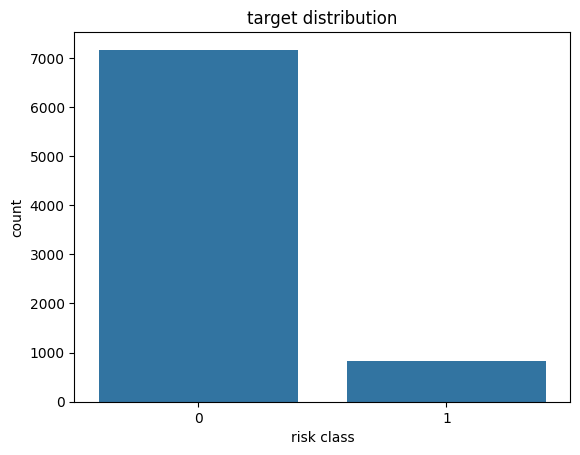

In [13]:
sns.countplot(data=df, x=target)
plt.title("target distribution")
plt.xlabel("risk class")
plt.ylabel("count")
plt.show()

In [14]:
df = df.copy()

In [15]:
duplicate_count = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

print("duplicates removed:", duplicate_count)

duplicates removed: 0


In [16]:
print("missing target values:", df[target].isnull().sum())

missing target values: 0


In [17]:
df = df.dropna(subset=[target]).copy()


In [18]:
print("remaining rows and columns:", df.shape)


remaining rows and columns: (8000, 14)


In [19]:
print("\nmissing values after initial cleaning:")
print(df.isnull().sum())


missing values after initial cleaning:
age_years                         0
sex_female                        0
bmi                               0
systolic_bp_mmHg                  0
diastolic_bp_mmHg                 0
total_cholesterol_mg_dL           0
fasting_glucose_mg_dL             0
resting_heart_rate_bpm            0
smoking_current                   0
family_history_cardiometabolic    0
physical_activity_level           0
sleep_hours                       0
stress_level_1_to_5               0
elevated_cardiometabolic_risk     0
dtype: int64


In [20]:
print("\nunique target values:")
print(sorted(df[target].unique()))

if not set(df[target].unique()).issubset({0, 1}):
    raise ValueError("target must contain only 0 and 1")


unique target values:
[np.int64(0), np.int64(1)]


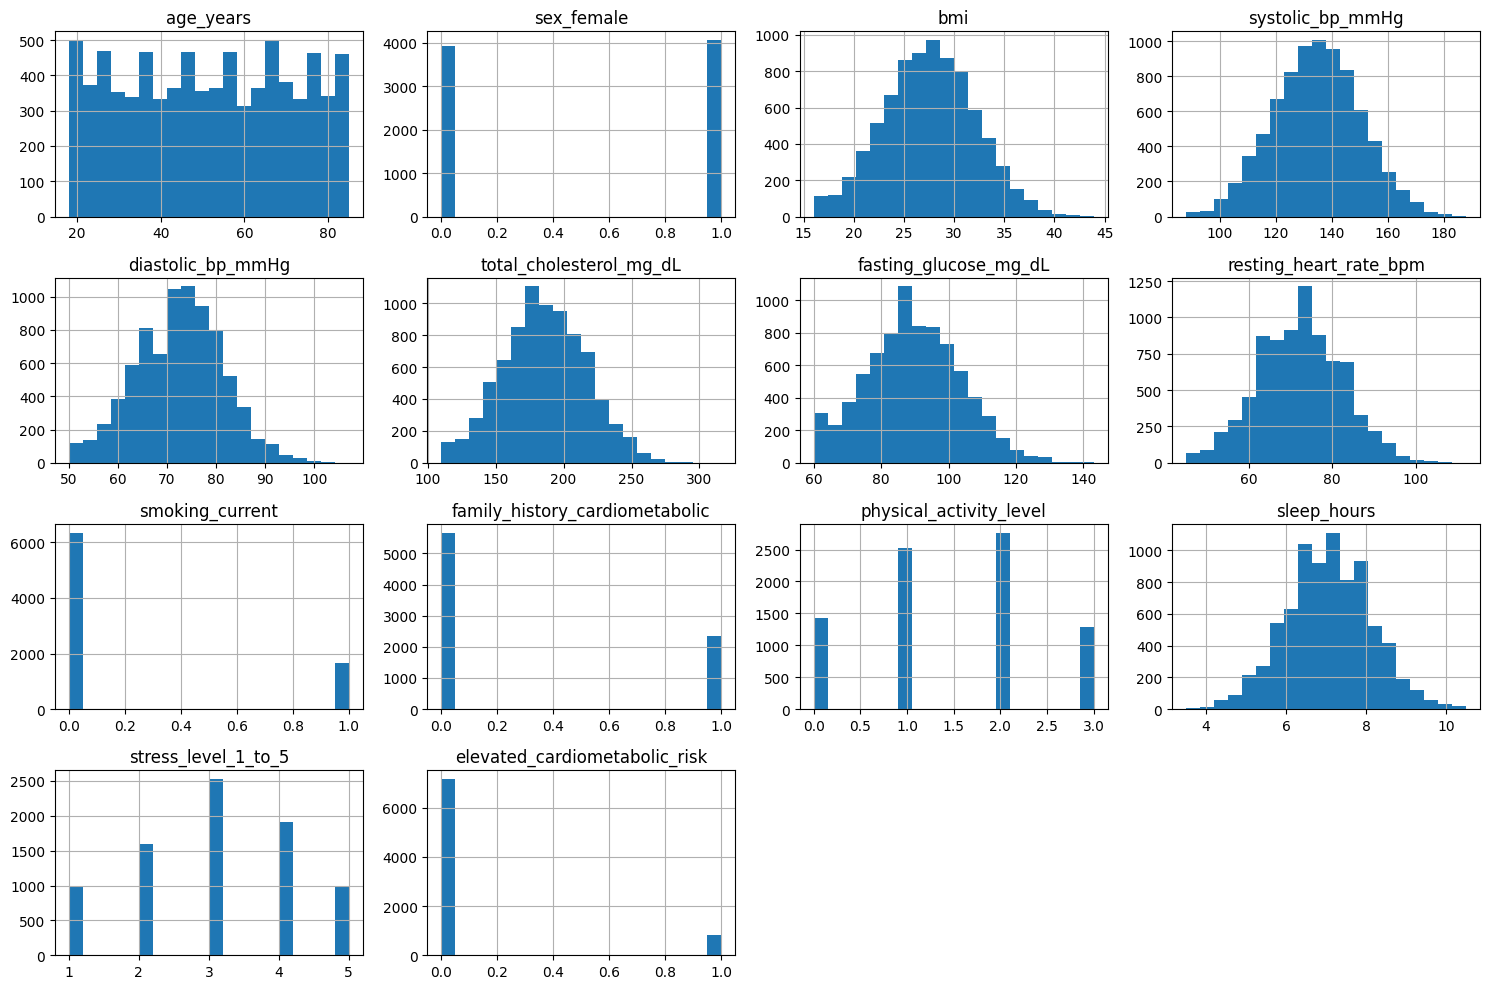

In [21]:
# numerical distributions

df.hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

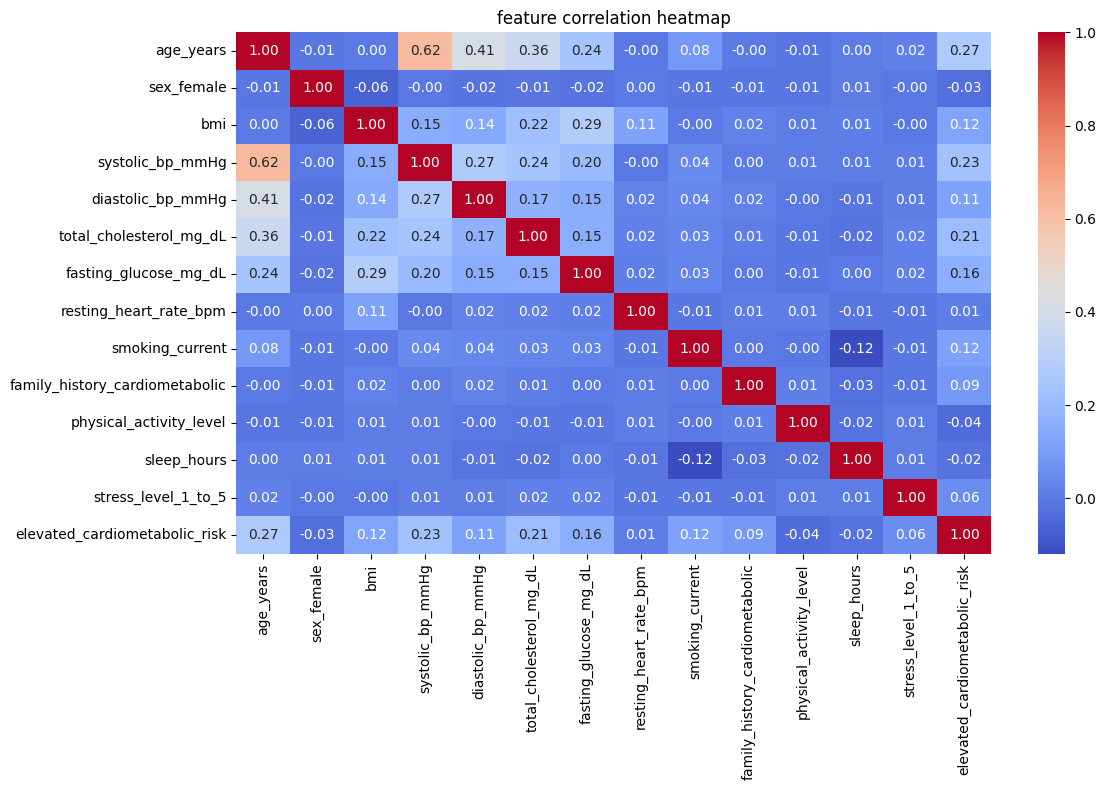

In [22]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("feature correlation heatmap")
plt.tight_layout()
plt.show()

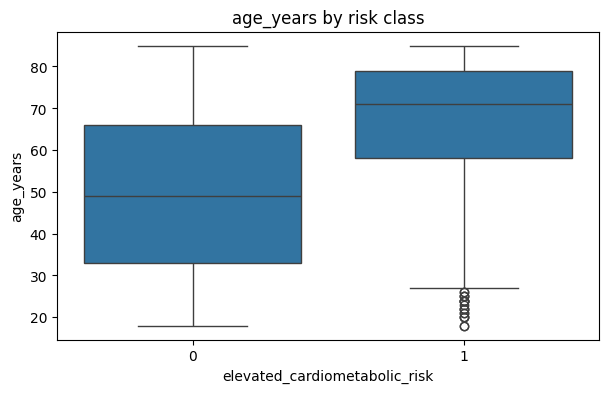

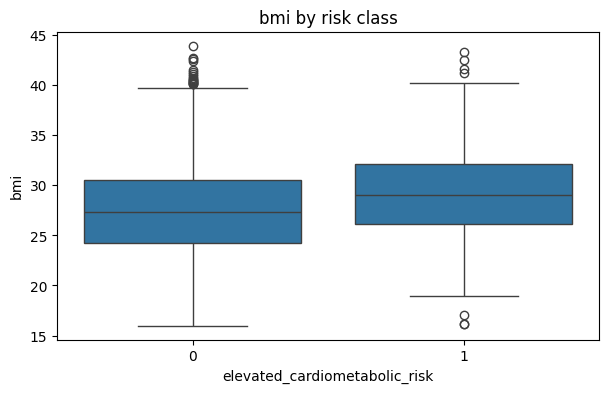

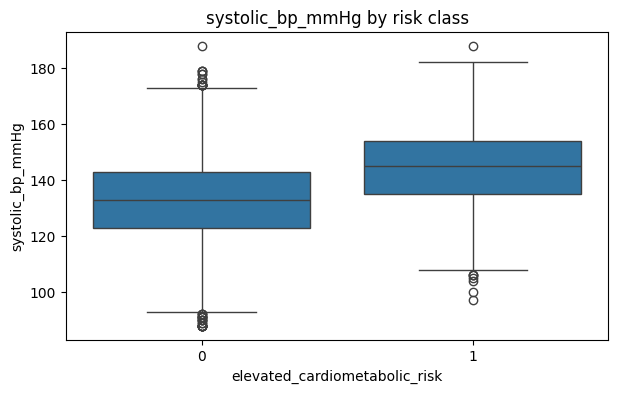

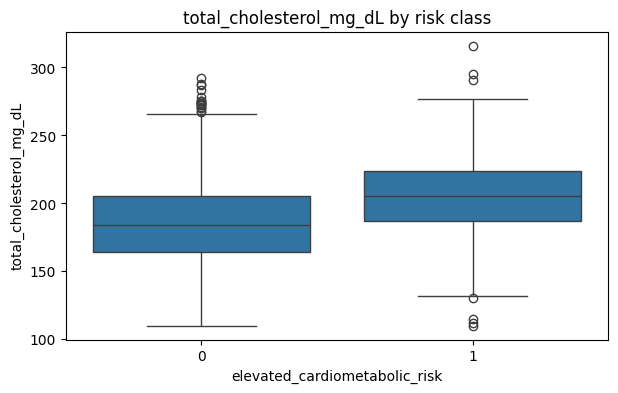

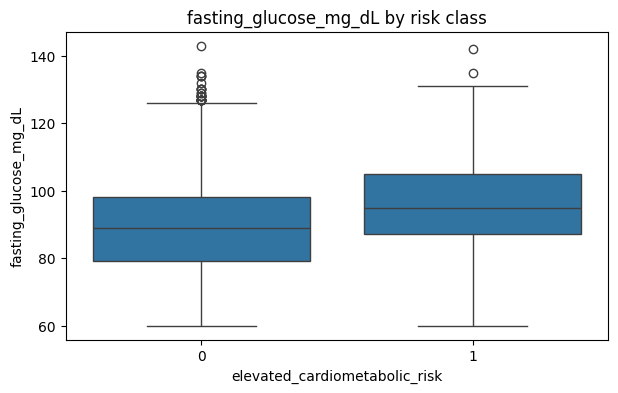

In [23]:
features = [
    "age_years",
    "bmi",
    "systolic_bp_mmHg",
    "total_cholesterol_mg_dL",
    "fasting_glucose_mg_dL"
]

for feature in features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=target, y=feature)
    plt.title(f"{feature} by risk class")
    plt.show()

In [24]:
#  create a new feature
df["pulse_pressure"] = (
    df["systolic_bp_mmHg"] - df["diastolic_bp_mmHg"]
)

print("new feature created")
display(df[[
    "systolic_bp_mmHg",
    "diastolic_bp_mmHg",
    "pulse_pressure"
]].head())

new feature created


,systolic_bp_mmHg,diastolic_bp_mmHg,pulse_pressure
0,149,71,78
1,136,59,77
2,150,80,70
3,119,60,59
4,145,70,75


In [25]:
#separate features and target

x = df.drop(columns=[target])
y = df[target].astype("int32")

print("feature shape:", x.shape)
print("target shape:", y.shape)

feature shape: (8000, 14)
target shape: (8000,)


In [26]:
# training and testing split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("training shape:", x_train.shape)
print("testing shape:", x_test.shape)

print("\ntraining target distribution:")
print(y_train.value_counts(normalize=True))

training shape: (6400, 14)
testing shape: (1600, 14)

training target distribution:
elevated_cardiometabolic_risk
0    0.895625
1    0.104375
Name: proportion, dtype: float64


In [27]:
#create the preprocessing pipeline

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("preprocessing pipeline created")

preprocessing pipeline created


In [28]:
## fit and transform the data

x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

print("training data processed:", x_train_processed.shape)
print("testing data processed:", x_test_processed.shape)

print("missing values after preprocessing:",
      np.isnan(x_train_processed).sum())

training data processed: (6400, 14)
testing data processed: (1600, 14)
missing values after preprocessing: 0


In [29]:
# create the ann model

model = Sequential([
    Input(shape=(x_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.30),
    Dense(32, activation="relu"),
    Dropout(0.20),
    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,073 (12.00 KB)

 Trainable params: 3,073 (12.00 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
#compile the ann

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("model compiled successfully")

model compiled successfully


In [31]:
# configure callbacks

os.makedirs("saved_model", exist_ok=True)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath="saved_model/best_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=0.00001,
        verbose=1
    )
]

print("callbacks configured successfully")

callbacks configured successfully


In [32]:
# train the ann

history = model.fit(
    x_train_processed,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    callbacks=callbacks,
    verbose=1
)

print("training completed")

Epoch 1/100
158/160 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8762 - auc: 0.6405 - loss: 0.3564 - precision: 0.1163 - recall: 0.0285
Epoch 1: val_loss improved from None to 0.28074, saving model to saved_model/best_model.keras

Epoch 1: finished saving model to saved_model/best_model.keras
160/160 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8770 - auc: 0.6430 - loss: 0.3543 - precision: 0.1163 - recall: 0.0282 - val_accuracy: 0.8930 - val_auc: 0.8050 - val_loss: 0.2807 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/100
143/160 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8973 - auc: 0.7662 - loss: 0.2897 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 2: val_loss improved from 0.28074 to 0.27388, saving model to saved_model/best_model.keras

Epoch 2: finished saving model to saved_model/best_model.keras
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8963 - auc: 0.7697 - loss: 0.2897 - precision: 0.0000e+00 - recall: 0.0000e+00

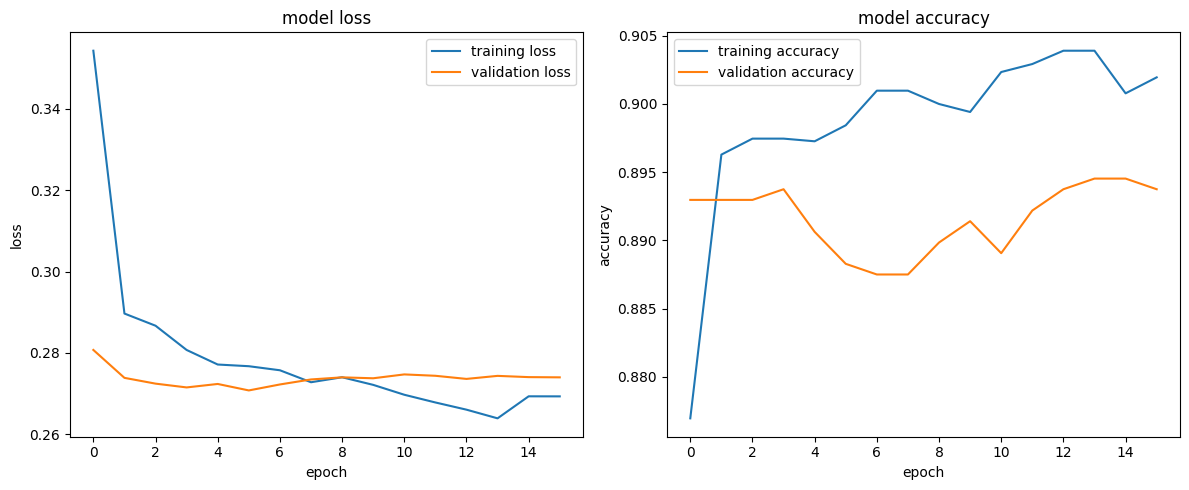

In [33]:
# plot loss and accuracy

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.title("model loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="training accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.title("model accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [34]:
#  evaluate on test data

test_results = model.evaluate(
    x_test_processed,
    y_test,
    verbose=0,
    return_dict=True
)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

accuracy: 0.8988
auc: 0.7944
loss: 0.2822
precision: 0.7273
recall: 0.0479


In [35]:
# classification report

y_prob = model.predict(x_test_processed, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["no elevated risk", "elevated risk"],
    zero_division=0
))

print("accuracy:", accuracy_score(y_test, y_pred))
print("precision:", precision_score(y_test, y_pred, zero_division=0))
print("recall:", recall_score(y_test, y_pred, zero_division=0))
print("f1 score:", f1_score(y_test, y_pred, zero_division=0))

if y_test.nunique() == 2:
    print("roc auc:", roc_auc_score(y_test, y_prob))

                  precision    recall  f1-score   support

no elevated risk       0.90      1.00      0.95      1433
   elevated risk       0.73      0.05      0.09       167

        accuracy                           0.90      1600
       macro avg       0.81      0.52      0.52      1600
    weighted avg       0.88      0.90      0.86      1600

accuracy: 0.89875
precision: 0.7272727272727273
recall: 0.04790419161676647
f1 score: 0.0898876404494382
roc auc: 0.7942259235889699


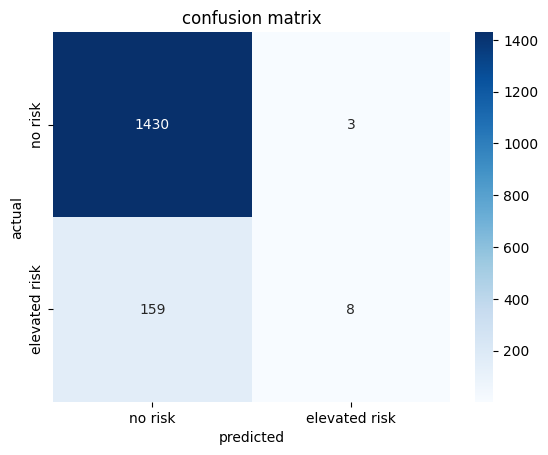

In [36]:
#  confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["no risk", "elevated risk"],
    yticklabels=["no risk", "elevated risk"]
)

plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("confusion matrix")
plt.show()

In [37]:
# save the model

os.makedirs("saved_model", exist_ok=True)

model.save("saved_model/cardiometabolic_ann.keras")

print("model saved successfully")

model saved successfully


In [38]:
# save preprocessing

os.makedirs("saved_preprocessing", exist_ok=True)

joblib.dump(
    preprocessor,
    "saved_preprocessing/preprocessor.joblib"
)

joblib.dump(
    x_train.columns.tolist(),
    "saved_preprocessing/feature_columns.joblib"
)

print("preprocessor saved")
print("feature column order saved")

preprocessor saved
feature column order saved


In [39]:
#  load saved model and preprocessing

loaded_model = load_model(
    "saved_model/cardiometabolic_ann.keras"
)

loaded_preprocessor = joblib.load(
    "saved_preprocessing/preprocessor.joblib"
)

feature_columns = joblib.load(
    "saved_preprocessing/feature_columns.joblib"
)

print("model loaded successfully")
print("preprocessing loaded successfully")

model loaded successfully
preprocessing loaded successfully


In [40]:
#  predict for one test record

new_data = x_test.iloc[[0]].copy()
new_data = new_data[feature_columns]

new_data_processed = loaded_preprocessor.transform(new_data)

probability = loaded_model.predict(
    new_data_processed,
    verbose=0
)[0, 0]

predicted_class = int(probability >= 0.5)

print("predicted probability:", round(float(probability), 4))
print("predicted class:", predicted_class)

if predicted_class == 1:
    print("prediction: elevated risk")
else:
    print("prediction: no elevated risk")

print("actual class:", int(y_test.iloc[0]))

predicted probability: 0.0019
predicted class: 0
prediction: no elevated risk
actual class: 0
